# Practice lab: the same audit on Rohan's lending book
*Feature engineering · Encoding and scaling · Leakage and the prediction-time question ·
The column audit · Feature importance and its limits*

**The real company.** Uber's machine learning platform, Michelangelo, predicts UberEATS
delivery time from features such as a restaurant's average preparation time over the last
seven days and over the last hour, kept in a feature store where "the same expressions are
applied at training time and at prediction time" (Uber Engineering blog, 5 September 2017,
verified 28 October 2026: https://www.uber.com/blog/michelangelo-machine-learning-platform/).
A feature there is a definition with a time stamp, never a loose column.

**The Kalpa twin.** Rohan Desai, head of risk at Kalpa Financial Services, wants Kalpa's
nudge method moved to loan approval. His team hands you a public stand-in for his book,
German Credit (1,000 applications from a Hamburg bank, 30 percent bad), and one rule from
Tuesday: approving a bad loan costs five times a wrongful rejection.

**Who needs the answer.** Rohan, who signs the approval rule, and his solution architect,
who decides which feeds the scoring service may read on the day an application arrives.

**How it runs.** The TA re-runs case 3 for ten minutes, then the room works through six
steps. Each TODO cell runs as shipped and prints that it is open; fill it, run it, and the
check below it reports PASS. About 90 minutes.

## Which question does each seat ask before any code?
| Seat | The question for this book |
|---|---|
| Business owner (Rohan) | What does a bad approval cost against a wrong rejection, and which rule do I sign? |
| Product manager | What does an applicant see when the model says no, and how fast? |
| Solution architect | Which columns exist on the day the application arrives? |
| Senior ML engineer | Does the score hold up when a column is shuffled or the target is scrambled? |
| Implementation engineer | Are the encoder and scaler fitted on training rows inside the pipeline? |
| QA and tester | What test would fail if a column written after approval slipped in? |

In [1]:
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False})
INK, VIOLET, ROSE, GREEN, GREY = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#A9A3D2"

def check(label, ok):
    """Print one line that starts PASS or FAIL, and keep the notebook running either way."""
    print(("PASS  " if ok else "FAIL  ") + label)

import pathlib, sqlite3
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.inspection import permutation_importance

CACHE = pathlib.Path.home() / ".cache" / "c2_datasets"
CACHE.mkdir(parents=True, exist_ok=True)
# German Credit (Statlog), OpenML credit-g: 1,000 loan applications, 30 percent bad; cached after the first fetch.
credit = fetch_openml(name="credit-g", version=1, as_frame=True, data_home=str(CACHE / "openml")).frame
credit["bad"] = (credit["class"] == "bad").astype(int)
INPUTS = [c for c in credit.columns if c not in ("class", "bad")]

def pipe(columns, df):
    num = [c for c in columns if pd.api.types.is_numeric_dtype(df[c])]
    cat = [c for c in columns if c not in num]
    prep = ColumnTransformer([("num", StandardScaler(), num),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=2000))])

train, val = train_test_split(credit, test_size=0.25, stratify=credit["bad"], random_state=42)
print(f"{len(credit):,} applications, {credit['bad'].mean():.0%} bad; train {len(train)}, validation {len(val)}")

1,000 applications, 30% bad; train 750, validation 250


## Step 1: which ratio carries the monthly load of a loan?
`credit_amount` is the loan in Deutsche Mark and `duration` is the loan's length in months,
asked for on the application. Build `monthly_burden`, the amount per month, and write the
reason Rohan would repeat.

In [2]:
monthly_burden = credit["credit_amount"] / credit["duration"]
reason_1 = "the monthly instalment is what has to be paid from each salary"
print(monthly_burden.describe().round(0).to_dict())

{'count': 1000.0, 'mean': 168.0, 'std': 153.0, 'min': 24.0, '25%': 90.0, '50%': 130.0, '75%': 206.0, 'max': 2483.0}


In [3]:
if monthly_burden is not None:
    credit["monthly_burden"] = monthly_burden
    check("monthly_burden has a value for all 1,000 applications", credit["monthly_burden"].notna().sum() == 1000)
    check("the median monthly burden sits between 100 and 200 DM", 100 < credit["monthly_burden"].median() < 200)
else:
    print("Waiting for TODO 1.")

PASS  monthly_burden has a value for all 1,000 applications
PASS  the median monthly burden sits between 100 and 200 DM


## Step 2: which encoder for checking_status, in a logistic model?
`checking_status` has four levels: `<0`, `0<=X<200`, `>=200` and `no checking`. Three look
ordered and the fourth does not. Pick the encoding for a logistic model and say why.

(A) a code 1 to 4 in the order above; (B) one-hot, four columns; (C) drop it.

In [4]:
choice_2 = "B"
reason_2 = "no checking account is a different kind of applicant, not a fifth balance band"
print(f"chosen: {choice_2}")

chosen: B


In [5]:
levels = sorted(credit["checking_status"].astype(str).unique())
print("levels:", levels)
check("checking_status has four levels", len(levels) == 4)
if choice_2 is not None:
    check("one-hot chosen for the logistic model", choice_2 == "B")

levels: ['0<=X<200', '<0', '>=200', 'no checking']
PASS  checking_status has four levels
PASS  one-hot chosen for the logistic model


## Step 3: which columns pass the prediction-time question on the day an application arrives?
All 20 inputs come from the application form or the credit bureau. Two more columns are
offered by the collections team, and are described here, never added: `collections_flag`
(set when a loan falls 60 days behind) and `months_in_arrears` (updated every month after the
loan starts). Mark each of the four below `known` or `not known`.

In [6]:
audit = {"duration": "known", "credit_history": "known",
         "collections_flag": "not known", "months_in_arrears": "not known"}
print("TODO 3 is open for:", [k for k, v in audit.items() if v is None])

TODO 3 is open for: []


In [7]:
if None not in audit.values():
    check("duration here is the requested loan length, known on the form", audit["duration"] == "known")
    check("both collections columns are written after the loan starts",
          audit["collections_flag"] == audit["months_in_arrears"] == "not known")
else:
    print("Waiting for TODO 3.")

PASS  duration here is the requested loan length, known on the form
PASS  both collections columns are written after the loan starts


**Why the name is a trap.** The bank's `duration` on Wednesday was the length of a call,
written when the call ended. Here `duration` is the length of the loan the applicant asks
for, written on the form. Same name, opposite verdict: the audit reads the time stamp, never
the column name.

## Step 4: what does the honest model score, with and without the ratio?
Fit the pipeline on the 750 training rows and score the 250 validation rows.

In [8]:
train, val = train_test_split(credit, test_size=0.25, stratify=credit["bad"], random_state=42)
def auc(cols):
    model = pipe(cols, train).fit(train[cols], train["bad"])
    return roc_auc_score(val["bad"], model.predict_proba(val[cols])[:, 1])
print(f"20 inputs: AUC {auc(INPUTS):.4f}; with monthly_burden: {auc(INPUTS + ['monthly_burden']):.4f}")

20 inputs: AUC 0.8043; with monthly_burden: 0.8055


In [9]:
if auc(INPUTS) is not None:
    check("the honest model ranks well above a coin", auc(INPUTS) > 0.75)
    check("the ratio moves AUC by less than 0.02", abs(auc(INPUTS + ["monthly_burden"]) - auc(INPUTS)) < 0.02)
else:
    print("Waiting for TODO 4.")

PASS  the honest model ranks well above a coin


PASS  the ratio moves AUC by less than 0.02


## Step 5: does SQL from Week 2 tell the same story as the model?
The integration step: put the applications in an in-memory SQLite table and count the bad
rate by `checking_status`, the way Week 2 counted by segment.

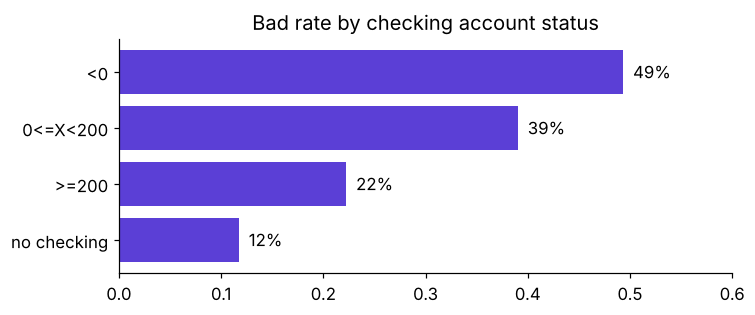

PASS  the four groups add up to 1,000 applications


,checking_status,applications,bad_rate
0,<0,274,0.493
1,0<=X<200,269,0.390
2,>=200,63,0.222
3,no checking,394,0.117


In [10]:
con = sqlite3.connect(":memory:")
credit[["checking_status", "bad"]].astype({"checking_status": str}).to_sql("loans", con, index=False)
by_status = pd.read_sql("""
    SELECT checking_status, COUNT(*) AS applications, ROUND(AVG(bad), 3) AS bad_rate
    FROM loans GROUP BY checking_status ORDER BY bad_rate DESC""", con)
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(by_status["checking_status"], by_status["bad_rate"], color=VIOLET)
for i, v in enumerate(by_status["bad_rate"]):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center")
ax.invert_yaxis(); ax.set_xlim(0, 0.6); ax.set_title("Bad rate by checking account status")
plt.tight_layout(); plt.show()
check("the four groups add up to 1,000 applications", int(by_status["applications"].sum()) == 1000)
by_status

## Step 6: can QA break it?
Two attacks. First, scramble the target in the training rows: an honest pipeline should fall
to about a coin, because nothing real is left to learn. Second, read the importance chart
and ask whether its top column is a lever.

In [11]:
rng = np.random.default_rng(42)
scrambled = pipe(INPUTS, train).fit(train[INPUTS], rng.permutation(train["bad"].values))
a_scrambled = roc_auc_score(val["bad"], scrambled.predict_proba(val[INPUTS])[:, 1])
model = pipe(INPUTS, train).fit(train[INPUTS], train["bad"])
perm = permutation_importance(model, val[INPUTS], val["bad"], scoring="roc_auc", n_repeats=5, random_state=42)
top = pd.Series(perm.importances_mean, index=INPUTS).sort_values(ascending=False).head(5).round(3)
print(f"AUC with a scrambled target: {a_scrambled:.3f}")
print(top.to_string())
check("a scrambled target scores near a coin", 0.35 < a_scrambled < 0.65)
check("checking_status tops the importance chart", top.index[0] == "checking_status")

AUC with a scrambled target: 0.424
checking_status    0.068
purpose            0.027
credit_amount      0.024
duration           0.020
credit_history     0.018
PASS  a scrambled target scores near a coin
PASS  checking_status tops the importance chart


**Read it.** The scrambled model lands near 0.5 on 250 rows (a few points either side is
noise), so the pipeline is not leaking the answer through its preprocessing. `checking_status`
tops the chart; opening a checking account for an applicant would not make them repay, since
the status reflects how they already manage money. A lever needs a fair test.

## The assignment: one more feature, with its reason
Build one more feature from the application (for example, a flag for applicants under 25, or
the loan amount per existing credit), state its reason in one sentence, run the
prediction-time question on it, and report the AUC with and without it.

In [12]:
credit["under_25"] = (credit["age"] < 25).astype(int)
train, val = train_test_split(credit, test_size=0.25, stratify=credit["bad"], random_state=42)
my_feature = "under_25"
print("bad rate by under_25:", credit.groupby("under_25")["bad"].mean().round(3).to_dict())
print(f"AUC without {auc(INPUTS):.4f}, with {auc(INPUTS + ['under_25']):.4f}: age already carries it")

bad rate by under_25: {0: 0.281, 1: 0.409}
AUC without 0.8043, with 0.7986: age already carries it


## The write-up, in five lines
| Line | Model write-up |
|---|---|
| Claim | The honest application model ranks bad loans at AUC 0.80 on 250 held-out applications |
| Evidence | Every input passes the prediction-time question; a scrambled target scores near a coin |
| Caveat | The collections columns would lift the score and must never enter: they are written after the loan starts |
| Action | Approve below the cost threshold from Tuesday's 5:1 rule (reject when P(bad) is above 1/6), and review monthly |
| What would change my mind | A feature whose write time the bureau cannot confirm, or a drop when scored on later applications |